# Lesson 12: CSV to `geoDataFrame` + Streamline your code

Before class, make sure you can import the data we will use in [lesson 12](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/lesson-11-csv-to-geo.html). Run the three code cells in this notebook. If they all run without errors, you are ready for class!

By the end of lesson 12, you will be able to:

- create a `geopandas.GeoDataFrame` from a CSV with longitude and latitude columns
- format printed output using f-strings
- use `for` loops, alone and with `zip()`, to avoid repeating code
- check that your code does what you expect using `assert`
- create figures with multiple axes
- write functions with docstrings to reuse code

## About the data

We will use two datasets:

1. **Power plants**: a CSV with the operable electric generating plants in the United States by energy source, as of February 2025, from the U.S. Energy Information Administration (EIA). We will read it directly from its URL, so you don't need to download it. See the [dataset's page and metadata](https://hub.arcgis.com/datasets/fedmaps::power-plants-in-the-u-s--2/about).

2. **US states**: the 2026 TIGER shapefile of the US states from the United States Census Bureau. See the [TIGER/Line shapefiles page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) and the [technical documentation](https://www2.census.gov/geo/pdfs/maps-data/data/tiger/tgrshp2026/TGRSHP2026_TechDoc.pdf) for the metadata. To download it:
    1. At the [2026 TIGER page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html), under Download, click on "Web Interface".
    2. For year, select 2026, and for layer type select "States (and equivalent)". Click submit.
    3. Click on "Download national file".
    4. Unzip the file and move the `tl_2026_us_state` folder into a `data/` folder at the same level as this notebook.

Read the information about both datasets in the [lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/lesson-11-csv-to-geo.html) before class.

## Import libraries

In [1]:
import os

import pandas as pd
from pandas.api.types import is_string_dtype, is_numeric_dtype
import geopandas as gpd
import matplotlib.pyplot as plt


# Display all columns when looking at dataframes
pd.set_option("display.max_columns", None)

## Import power plants data

In [2]:
URL = 'https://raw.githubusercontent.com/carmengg/eds-220-book/refs/heads/main/data/power_plants_epsg4269.csv'
power_plants = pd.read_csv(URL)

power_plants.head(3)

,objectid,plant_code,plant_name,utility_id,utility_name,sector_name,street_address,city,county,state,zip,primsource,source_desc,tech_desc,install_mw,total_mw,bat_mw,bio_mw,coal_mw,geo_mw,hydro_mw,hydrops_mw,ng_mw,nuclear_mw,crude_mw,solar_mw,wind_mw,other_mw,source,period,longitude,latitude
0,62897,1873,Tower,20910,Wolverine Power Supply Coop,Electric Utility,9663 Cooperative Road,Tower,Cheboygan,Michigan,49792,petroleum,Petroleum = 19.3 MW,Petroleum Liquids,21.3,19.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-84.294970,45.362818
1,62898,1874,Caro,18895,Thumb Electric Coop of Mich,Electric Utility,2437 East Dayton Road,Caro,Tuscola,Michigan,48723,petroleum,Petroleum = 8.5 MW,Petroleum Liquids,9.4,8.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.5,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-83.327806,43.465899
2,62899,1875,Ubly,18895,Thumb Electric Coop of Mich,Electric Utility,4159 Ubly Road,Ubly,Huron,Michigan,48475,petroleum,Petroleum = 12.3 MW,Petroleum Liquids,12.4,12.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-82.938806,43.721699


## Import US states shapefile

In [3]:
fp = os.path.join('data', 'tl_2026_us_state', 'tl_2026_us_state.shp')
states = gpd.read_file(fp)

states.head(3)

ERROR 1: PROJ: proj_create_from_database: Open of /opt/miniforge3/envs/eds220-v2/share/proj failed


,REGION,DIVISION,STATEFP,STATENS,GEOID,GEOIDFQ,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."


## Create geodataframe from csv

Known from metadata: CRS of the power plants data has the code EPSG:4269

In [4]:
# Create points from lat long
points = gpd.points_from_xy(power_plants['longitude'],
                   power_plants['latitude']\
                  )
# Create geodataframe
power_plants = gpd.GeoDataFrame(power_plants,    # Data
                                geometry=points, # Set points from lat long to geometry
                                crs='EPSG:4269'  # Set CRS from metadata
                               )

In [5]:
power_plants.plot();

## f-string

CRS EPSG:4269


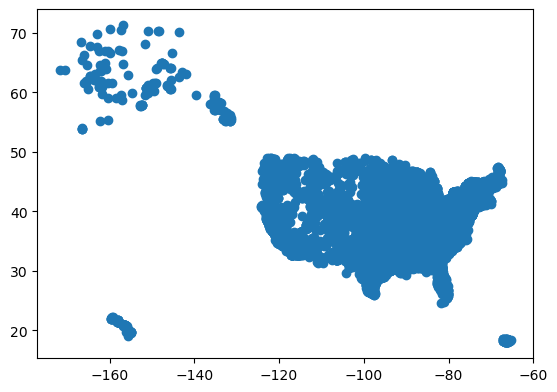

In [6]:
print('CRS', power_plants.crs)

In [7]:
print(f"ellipsoid: {power_plants.crs.ellipsoid}")

ellipsoid: GRS 1980


In [8]:
print(f"The data has {len(power_plants):,} power plants") # :, puts commas in number

print(f"Average installed capacity is {power_plants['install_mw'].mean():.2f} MW") # :.2f rounds to 2 decimals

The data has 13,445 power plants
Average installed capacity is 99.39 MW


## for loops

EPSG:4269


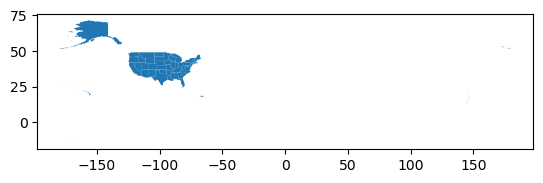

In [9]:
print(states.crs)
states.plot();

In [10]:
states.head(3)

,REGION,DIVISION,STATEFP,STATENS,GEOID,GEOIDFQ,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."


In [11]:
# Simplify column names
states.columns = states.columns.str.lower()
states.columns

Index(['region', 'division', 'statefp', 'statens', 'geoid', 'geoidfq',
       'stusps', 'name', 'lsad', 'mtfcc', 'funcstat', 'aland', 'awater',
       'intptlat', 'intptlon', 'geometry'],
      dtype='object')

In [12]:
# Check datatype of a few columns

print(f"regions is string dtype?: {is_string_dtype(states['region'])}")

# Another way of calling function
print(f"regions is string dtype?: {pd.api.types.is_string_dtype(states['region'])}")
# Note: sometimes when function is so far in package, makes sense to import function directly

print(f"statefp is string dtype?: {is_string_dtype(states['statefp'])}")
print(f"division is string dtype?: {is_string_dtype(states['division'])}")

regions is string dtype?: True
regions is string dtype?: True
statefp is string dtype?: True
division is string dtype?: True


In [13]:
code_cols = ['region', 'division', 'statefp']

# Check whether code columns are strings
for column in code_cols:
    print(f"{column} is string dtype?: {is_string_dtype(states[column])}")

region is string dtype?: True
division is string dtype?: True
statefp is string dtype?: True


## `assert`
We want to update the datatype of the columns from strings to integers. And we want to check it works without printing things

In [14]:
# Update code columns into integers
for column in code_cols:
    states[column] = states[column].astype('int')
    assert is_numeric_dtype(states[column])

How does assertion work?

In [15]:
2+2 ==4 # True statement

True

In [16]:
# Does nothing if statement is True
sum = 2+2
assert sum == 4

In [17]:
# Pops up as AssertionError if statement is False
sum = 3+2
assert sum == 4, "Sum is not equal to 4"

AssertionError: Sum is not equal to 4

## Subsetting data 

In [18]:
code_cols

['region', 'division', 'statefp']

In [22]:
for column in code_cols:
    print(f"{column}: {sorted(states[column].unique())}")

region: [1, 2, 3, 4, 9]
division: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
statefp: [1, 2, 4, 5, 6, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 44, 45, 46, 47, 48, 49, 50, 51, 53, 54, 55, 56, 60, 66, 69, 72, 78]


In [26]:
states[states['region'] == 9]['name']

3                                   American Samoa
28                    United States Virgin Islands
47                                     Puerto Rico
53    Commonwealth of the Northern Mariana Islands
54                                            Guam
Name: name, dtype: object

In [33]:
# Select contiguous US states
contiguous = states[(states['region']!=9) & (~states['statefp'].isin([2,15]))] # `~` is a 'not' statement

In [44]:
# Select data in powerplants for contiguous US States
power_plants = power_plants[power_plants['state'].isin(contiguous['name'])]

In [45]:
power_plants['state'].unique()

array(['Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana',
       'Wyoming', 'Nebraska', 'Nevada', 'New Hampshire', 'Vermont',
       'New Jersey', 'New Mexico', 'New York', 'North Carolina',
       'North Dakota', 'Ohio', 'Georgia', 'Alabama', 'Texas',
       'California', 'Kentucky', 'Washington', 'Arizona', 'Kansas',
       'South Carolina', 'Florida', 'Utah', 'Oklahoma', 'Arkansas',
       'Illinois', 'Colorado', 'Connecticut', 'Massachusetts', 'Delaware',
       'Maryland', 'Idaho', 'Maine', 'Indiana', 'Iowa', 'Louisiana',
       'Wisconsin', 'Oregon', 'Pennsylvania', 'Rhode Island',
       'South Dakota', 'Tennessee', 'West Virginia', 'Virginia',
       'District of Columbia'], dtype=object)

In [46]:
assert contiguous.crs == power_plants.crs

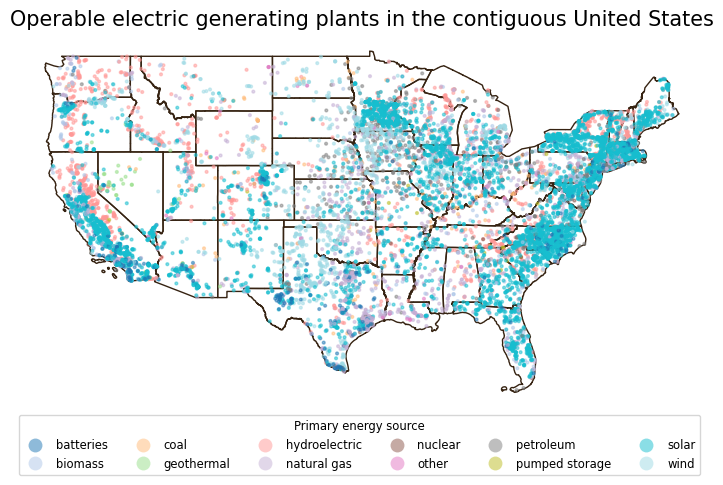

In [49]:
# Plot power plants
fig, ax = plt.subplots(figsize=(9, 5)) # Update figure size

# Remove the axis for a cleaner map
ax.axis('off')

# Title for the plot
ax.set_title('Operable electric generating plants in the contiguous United States', 
              fontsize=15)

# Add states
contiguous.plot(ax=ax,
               color='none',
               edgecolor='#362312')

# Add electric power plants colored by energy source
power_plants.plot(ax=ax, 
                  column='primsource',
                  legend=True,
                  markersize=4,
                  cmap='tab20',
                  alpha=0.5,
                  legend_kwds={
                      'title': 'Primary energy source',
                      'title_fontsize': 'small',
                      'fontsize': 'small',
                      'loc': 'upper left',
                      'bbox_to_anchor': (0, 0),
                      'ncols': 6  
                  })
                  
plt.show()

## `for` with `zip`
Often, we need to simultaneously iterate over two lists.
`zip()` lets you combine two or more lists to iterate over them

In [53]:
# Iterate over a single list
numbers = [1,2,3]
for x in numbers:
    print(x)

print('\n') # Blank line

# Iterate over two lists in pairs using zip()
numbers = [1,2,3]
letters = ['a','b','c']
for x, letter in zip(numbers, letters):
    print(x, letter)


1
2
3


1 a
2 b
3 c


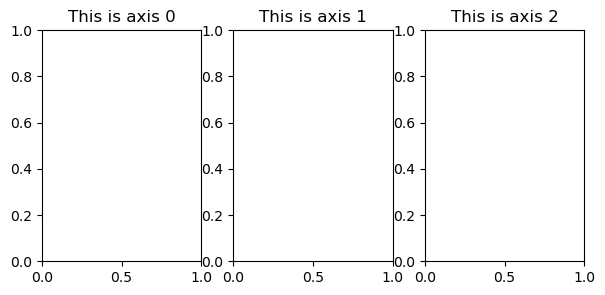

In [69]:
fig, axes = plt.subplots(nrows=1,ncols=3, figsize=(7,3))

# Instead of:
# axes[0].set_title('This is axis 0')
# axes[1].set_title('This is axis 1')
# axes[2].set_title('This is axis 2')

# Can do:
for ax, i in zip(axes, [0,1,2]):
    ax.set_title(f"This is axis {i}")

plt.show()

In [73]:
ca_power_plants = power_plants[power_plants['state'] == 'California']

In [75]:
ca_power_plants['primsource'].value_counts()

primsource
solar             865
natural gas       310
hydroelectric     238
wind              109
batteries         103
biomass            98
geothermal         33
petroleum          13
other              10
pumped storage      6
nuclear             1
coal                1
Name: count, dtype: int64

In [97]:
top_sources = ca_power_plants['primsource'].value_counts().index[:3].tolist()
top_sources

['solar', 'natural gas', 'hydroelectric']

In [81]:
ca_boundary = contiguous[contiguous['name'] == 'California']

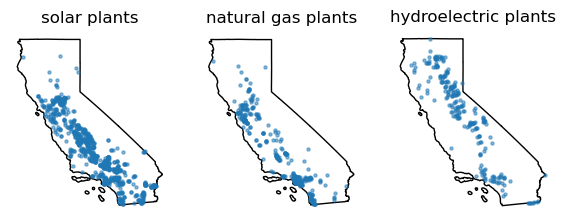

In [110]:
fig, axes = plt.subplots(nrows=1,ncols=3, figsize=(7,3))

for ax, source in zip(axes, top_sources):
    ca_boundary.plot(ax = ax, color='none')
    ax.set_title(f"{source} plants")
    subset = ca_power_plants[ca_power_plants['primsource'] == source]
    subset.plot(ax = ax, markersize=5, alpha = 0.5)
    ax.axis('off')

plt.show()